### 1. Import Libraries
Necessary libraries, including pandas, numpy, statsmodels etc are imported in order to carry out the Time series Forecasting.

In [5]:
# ============================================================
# ELECTRICITY DEMAND FORECASTING
# ============================================================

# Basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Time series decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

# Exponential Smoothing / ETS
from statsmodels.tsa.holtwinters import (
    ExponentialSmoothing,
    Holt
)

# ARIMA / SARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ACF and PACF plots
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Statistical tests
from statsmodels.tsa.stattools import adfuller

import warnings
warnings.filterwarnings("ignore")

### 2. Load the data
Basic operations like loading the data, checking the shape, datatypes, missing values of the data.

In [6]:
## IMporting the files

ip_path = "E://CSR//DS_AI_Analytixlabs//machine_lrng//Case_studies//13. Capstone Case Study - Demand_Estimation_Case_study//"
df = pd.read_csv(ip_path+"Electricity_Consumption.csv")

# Show first five rows
print(f"First five rows of the Dataframe:\n{df.head()}\n")

# Shape of the data
print(f"Shape of the dataset:\n{df.shape}\n")

# Check data types
print(f"The datatypes in the dataframe are:\n{df.dtypes}\n")

# Check missing values
print(f"Check missing values:\n{df.isnull().sum()}\n")

First five rows of the Dataframe:
       DATE  Electricty_Consumption_in_TW
0  1/1/1973                       35.9728
1  2/1/1973                       36.1334
2  3/1/1973                       35.0625
3  4/1/1973                       33.8416
4  5/1/1973                       33.5107

Shape of the dataset:
(561, 2)

The datatypes in the dataframe are:
DATE                             object
Electricty_Consumption_in_TW    float64
dtype: object

Check missing values:
DATE                            0
Electricty_Consumption_in_TW    0
dtype: int64



### 3. Data Preprocessing
Preprocessing the data includes converting to correct datatype, renaming columns, sorting in the chronological order, setting date as the index. 

In [7]:
# Renaming the columns names slightly
df.columns = ['Date','Electricty_Consumption (TW)']
print(df.head())

# Converting the Date to Datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Sort data chronologically in the ascening order
df = df.sort_values('Date')

# Set DATE as index
df.set_index('Date', inplace=True)

# Set monthly frequency
df = df.asfreq('MS')

# Display the processed data
print(f"Top rows of the data:\n {df.head()}")
print(f"\nBottom rows of the data:\n {df.tail()}")

# Check for missing values after setting monthly frequency
print("Missing values:\n")
print(df.isnull().sum())

       Date  Electricty_Consumption (TW)
0  1/1/1973                      35.9728
1  2/1/1973                      36.1334
2  3/1/1973                      35.0625
3  4/1/1973                      33.8416
4  5/1/1973                      33.5107
Top rows of the data:
             Electricty_Consumption (TW)
Date                                   
1973-01-01                      35.9728
1973-02-01                      36.1334
1973-03-01                      35.0625
1973-04-01                      33.8416
1973-05-01                      33.5107

Bottom rows of the data:
             Electricty_Consumption (TW)
Date                                   
2019-05-01                      97.5860
2019-06-01                     110.8580
2019-07-01                     122.1014
2019-08-01                     121.7765
2019-09-01                     109.7190
Missing values:

Electricty_Consumption (TW)    0
dtype: int64


### 4. Plotting the time series
A line plot of the time series with Date on the X axis and the electricity consumption on the Y axis is plotted. The variation of the time series and different components can be understood from here. 

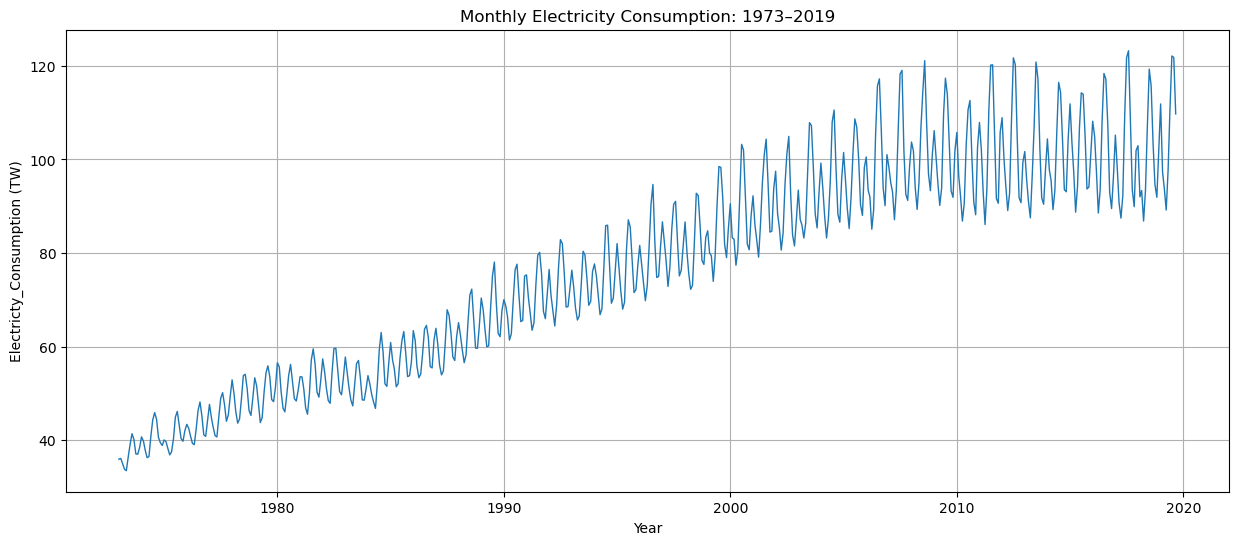

In [8]:
plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df['Electricty_Consumption (TW)'],
    linewidth=1
)

plt.title("Monthly Electricity Consumption: 1973–2019")
plt.xlabel("Year")
plt.ylabel("Electricty_Consumption (TW)")
plt.grid(True)
plt.show()


### 5. Look at yearly seasonality
In this step, the monthly variation of the electricity consumption is plotted across different years. The average consumption for each month across different years are calculated. This is to confirm the yearly seasonality.

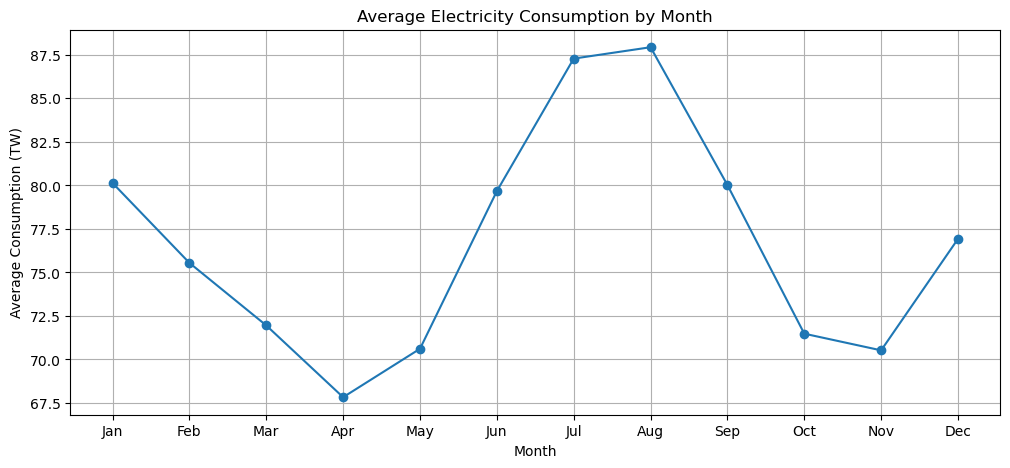

In [9]:
# Average consumption by calendar month

monthly_avg = df.groupby(
    df.index.month
)['Electricty_Consumption (TW)'].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 13),
    monthly_avg.values,
    marker='o'
)

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.title("Average Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Consumption (TW)")
plt.grid(True)
plt.show()

### 6. Seasonal decomposition
In this step, the time series is decomposed into Trend, seasonal and cyclic terms. Both additive and multiplicative models are used here.

<Figure size 1500x1000 with 0 Axes>

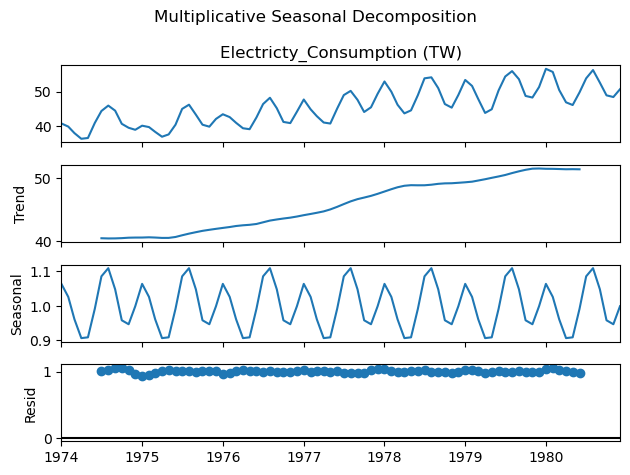

In [10]:
## Multiplicative decomposition

decomposition_mult = seasonal_decompose(
    df['Electricty_Consumption (TW)'].loc['1974':'1980'],
    model = 'multiplicatve'
)

plt.figure(figsize=(15, 10))
decomposition_mult.plot()
plt.suptitle(
    "Multiplicative Seasonal Decomposition",
    fontsize=12
)
plt.tight_layout()
plt.show()


<Figure size 1500x1000 with 0 Axes>

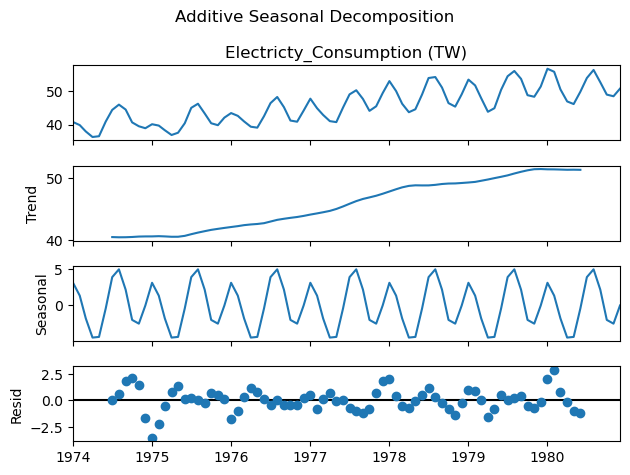

In [11]:
# Additive decomposition
decomposition_add = seasonal_decompose(
    df['Electricty_Consumption (TW)'].loc['1974':'1980'],
    model='additive'
)

plt.figure(figsize=(15, 10))
decomposition_add.plot()
plt.suptitle(
    "Additive Seasonal Decomposition",
    fontsize=12
)
plt.tight_layout()
plt.show()

### 7. Train-test split
The data is split into Train- Test data. The last 24 months is the validation/test set because the business wants a 1–2 year forecast.

In [12]:
# Last 24 months reserved for validation
train = df['Electricty_Consumption (TW)'].iloc[:-23]

test = df['Electricty_Consumption (TW)'].iloc[-24:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 538
Testing observations: 24

Training period:
1973-01-01 00:00:00 to 2017-10-01 00:00:00

Testing period:
2017-10-01 00:00:00 to 2019-09-01 00:00:00


### 8. Plot train and test data

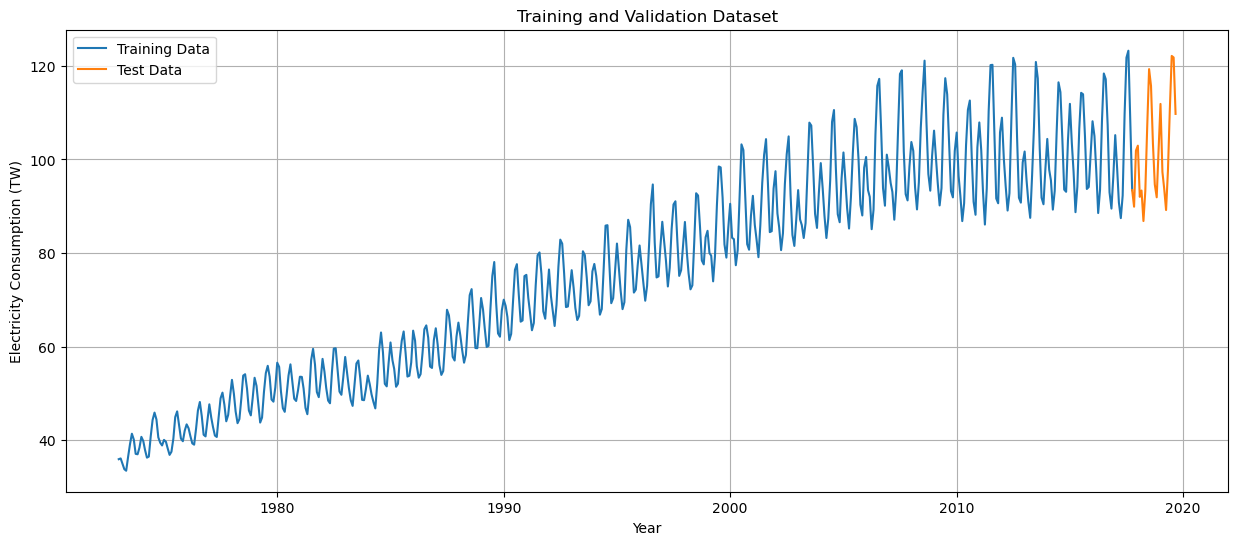

In [13]:
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train,
    label='Training Data'
)

plt.plot(
    test.index,
    test,
    label='Test Data'
)

plt.title("Training and Validation Dataset")
plt.xlabel("Year")
plt.ylabel("Electricity Consumption (TW)")
plt.legend()
plt.grid(True)
plt.show()

### 9. Define evaluation metrics
In the below step, reusable functions are created to evaluate the metrics: RMSE, MAPE, RMSPE

RMSE (Root Mean Square Error)  = square root of the average of the squared differences between predicted values and actual observed values
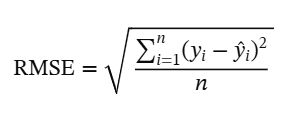

MAPE (Mean Absolute Percentage Error) = Average of the absolute percentage errors between actual and forecasted values.
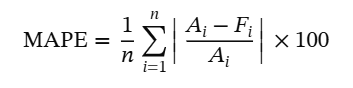

RMSPE (Root Mean Squared Percentage Error) = Square root of the average of squared percentage errors
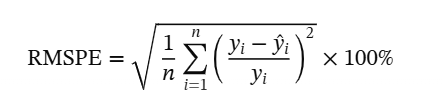

In [54]:
def calculate_metrics(actual, predicted):
    """
    Calculate RMSE, MAPE and RMSPE.
    """

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    # RMSE
    rmse = np.sqrt(
        np.mean((actual - predicted) ** 2)
    )

    # MAPE
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    # RMSPE
    rmspe = np.sqrt(
        np.mean(
            ((actual - predicted) / actual) ** 2
        )
    ) * 100

    return rmse, mape, rmspe

### 10. Create a model-results table

In the below step, a reusable function that generates metrics for each model and tabulates in a list

In [15]:
results = []

def evaluate_model(model_name, actual, predicted):

    rmse, mape, rmspe = calculate_metrics(
        actual,
        predicted
    )

    results.append({
        'Model': model_name,
        'RMSE': rmse,
        'MAPE (%)': mape,
        'RMSPE (%)': rmspe
    })

### 11. Model 1 — Holt's Linear Trend
In this step, the first model, namely 'The Holt's Linear Trend', also known as Double Exponential Smoothing is fitted. This model provides a simple baseline for forecasting. 

In [31]:
# Fit Holt's Linear Trend model

holt_model = Holt(
    train,
    initialization_method='estimated'
).fit(
    optimized=True
)

# Forecast validation period
holt_pred = holt_model.forecast(24)

# Evaluate
evaluate_model(
    'Holt Linear Trend',
    test,
    holt_pred
)

### 12. Model 2 — ETS / Exponential Smoothing
Because the data is monthly and seasonal, use a seasonal ETS model.

##### ETS model with additive trend and additive seasonality

In [17]:
ets_add = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='add',
    seasonal_periods=12,
    initialization_method='estimated'
).fit(
    optimized=True
)

ets_add_pred = ets_add.forecast(24)

evaluate_model(
    'ETS Additive Trend + Additive Seasonality',
    test,
    ets_add_pred
)

##### ETS model with additive trend and multiplicative seasonality

In [55]:
ets_mul = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='mul',
    seasonal_periods=12,
    initialization_method='estimated'
).fit(
    optimized=True
)

ets_mul_pred = ets_mul.forecast(24)

evaluate_model(
    'ETS Additive Trend + Multiplicative Seasonality',
    test,
    ets_mul_pred
)

### 13. Plot ETS predictions

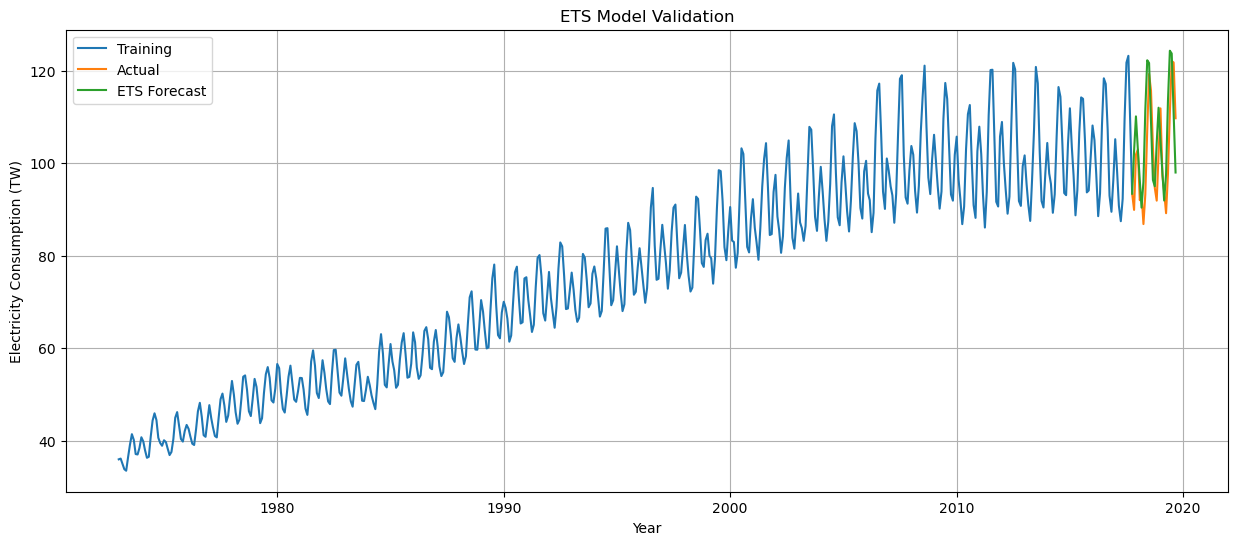

In [19]:
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train,
    label='Training'
)

plt.plot(
    test.index,
    test,
    label='Actual'
)

plt.plot(
    test.index,
    ets_mul_pred,
    label='ETS Forecast'
)

plt.title("ETS Model Validation")
plt.xlabel("Year")
plt.ylabel("Electricity Consumption (TW)")
plt.legend()
plt.grid(True)
plt.show()

### 14. Check stationarity — ADF test

Before ARIMA/SARIMA, an Augmented Dickey-Fuller test is performed to check for the Stationarity of the Series. A P_value less than 0.05 implies that the series is stationary and anything above is considered non-stationary.

In [34]:
def adf_test(series):

    result = adfuller(series.dropna())

    print("ADF Statistic:", result[0])
    print("p-value:", result[1])

    print("\nCritical Values:")

    for key, value in result[4].items():
        print(f"{key}: {value}")

    if result[1] <= 0.05:
        print("\nConclusion: Series is stationary")
    else:
        print("\nConclusion: Series is not stationary")


adf_test(train)
adf_test(train.diff().dropna())

ADF Statistic: -1.859957176023806
p-value: 0.35112649311406313

Critical Values:
1%: -3.4429395567097445
5%: -2.8670927932098063
10%: -2.569727435298953

Conclusion: Series is not stationary
ADF Statistic: -7.828783333818754
p-value: 6.375283431549349e-12

Critical Values:
1%: -3.4429395567097445
5%: -2.8670927932098063
10%: -2.569727435298953

Conclusion: Series is stationary


### 15. ACF and PACF

ACF and PACF plots are useful for determining the ARIMA parameters, q an p respectively. Since the ADF test above gave the conclusion that the time series is not stationary, a differencing of d = 1 is applied. Note that, the first difference ( d= 1) is used for calculating the ACF and PACF plots

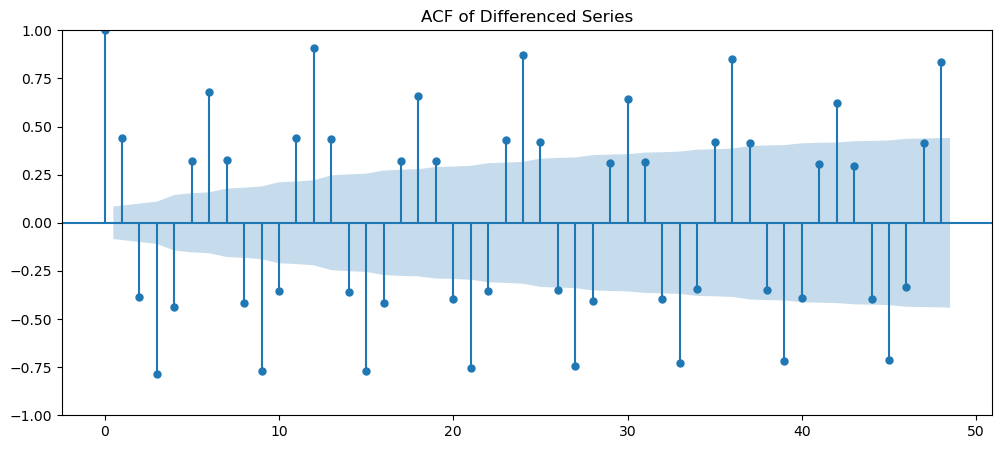

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    train.diff().dropna(),
    lags=48,
    ax=ax
)

plt.title("ACF of Differenced Series")
plt.show()

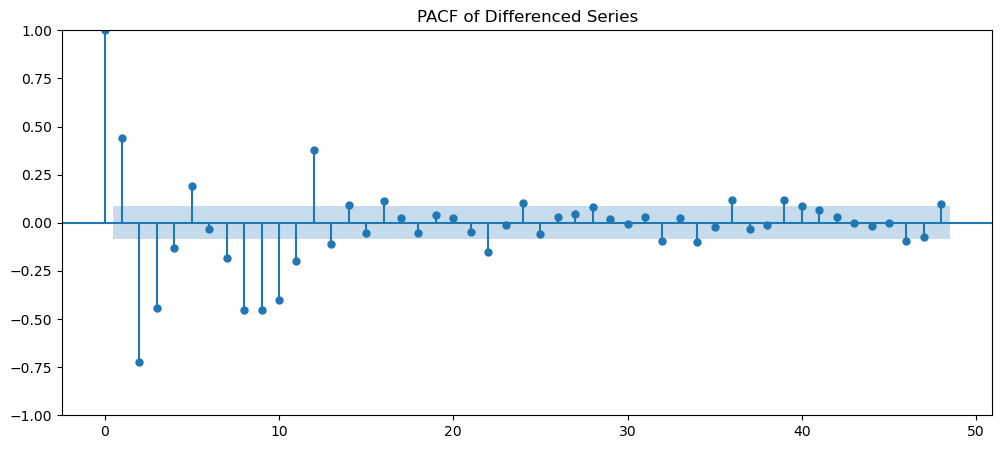

In [22]:
fig, ax = plt.subplots(figsize=(12, 5))

plot_pacf(
    train.diff().dropna(),
    lags=48,
    ax=ax,
    method='ywm'
)

plt.title("PACF of Differenced Series")
plt.show()

#### From the ACF plot, it can be seen that it's not decaying and similar seasonal spikes occur at 24, 36, 48 lags. That is a very strong indication of remaining annual seasonality. So the ACF is not showing a clean MA(q) cutoff. The PACF plot isn't showing a clean cutoff either. 


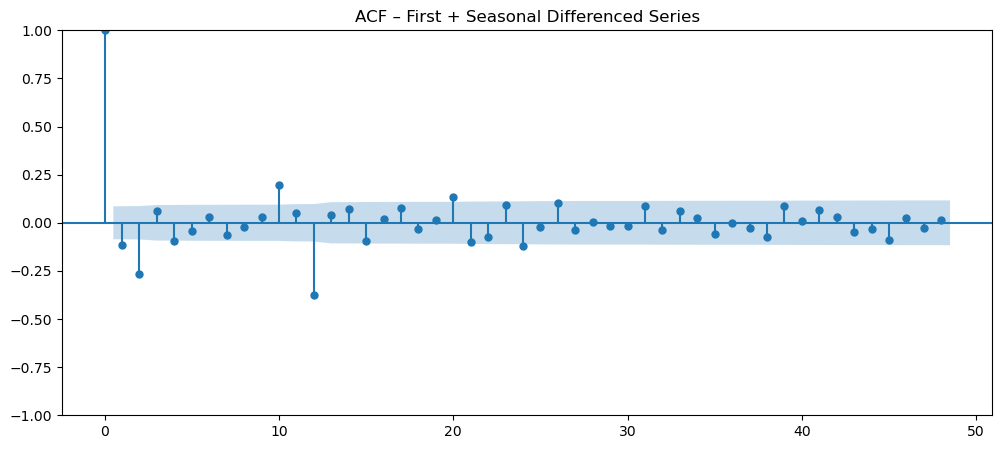

In [23]:
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    train.diff().diff(12).dropna(),
    lags=48,
    ax=ax
)

plt.title("ACF – First + Seasonal Differenced Series")
plt.show()


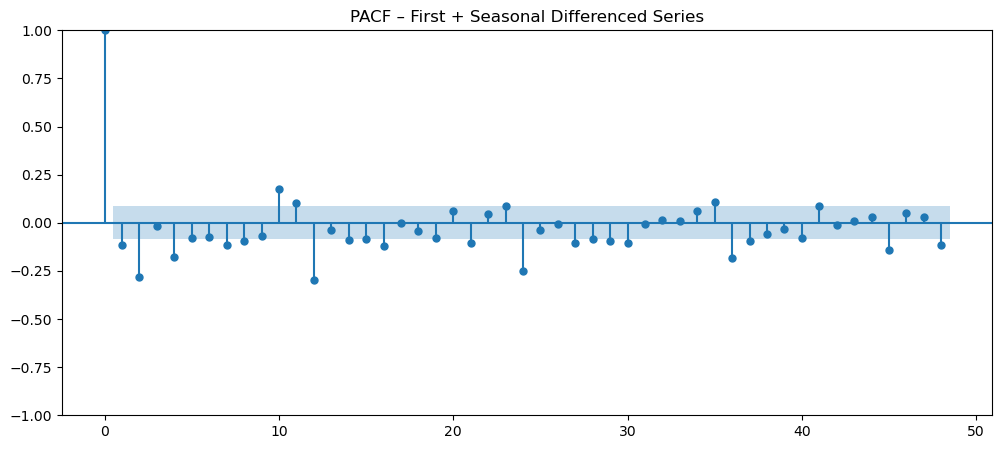

In [24]:
fig, ax = plt.subplots(figsize=(12, 5))

plot_pacf(
    train.diff().diff(12).dropna(),
    lags=48,
    ax=ax,
    method='ywm'
)

plt.title("PACF – First + Seasonal Differenced Series")
plt.show()

#### 16 SARIMA models
Instead of selecting only one SARIMA model, several combinations are evaluated. 
The general form is:
SARIMA(p,d,q)(P,D,Q,12)
where 12 represents yearly seasonality.

In [25]:
candidate_models = [
    ((1,1,1), (0,1,1,12)),
    ((1,1,2), (0,1,1,12)),
    ((2,1,1), (0,1,1,12)),
    ((2,1,2), (0,1,1,12)),

    ((1,1,1), (1,1,1,12)),
    ((1,1,2), (1,1,1,12)),
    ((2,1,1), (1,1,1,12)),
    ((2,1,2), (1,1,1,12))
]

##### Fitting all the above models

In [57]:
sarima_predictions = {}

for order, seasonal_order in candidate_models:

    model_name = (
        f"SARIMA{order}"
        f"x{seasonal_order}"
    )

    print("Fitting:", model_name)

    try:

        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(
            disp=False
        )

        prediction = fitted_model.forecast(
            steps=24
        )

        sarima_predictions[model_name] = prediction

        evaluate_model(
            model_name,
            test,
            prediction
        )

    except Exception as e:

        print(
            f"Could not fit {model_name}: {e}"
        )

Fitting: SARIMA(1, 1, 1)x(0, 1, 1, 12)
Fitting: SARIMA(1, 1, 2)x(0, 1, 1, 12)
Fitting: SARIMA(2, 1, 1)x(0, 1, 1, 12)
Fitting: SARIMA(2, 1, 2)x(0, 1, 1, 12)
Fitting: SARIMA(1, 1, 1)x(1, 1, 1, 12)
Fitting: SARIMA(1, 1, 2)x(1, 1, 1, 12)
Fitting: SARIMA(2, 1, 1)x(1, 1, 1, 12)
Fitting: SARIMA(2, 1, 2)x(1, 1, 1, 12)


In [45]:
results_df = pd.DataFrame(results)

# Sort based on RMSE
results_df = results_df.sort_values(
    by='RMSE'
).reset_index(drop=True)

print(results_df)

                                              Model       RMSE  MAPE (%)  \
0                     SARIMA(2, 1, 1)x(1, 1, 1, 12)   8.503933  7.092739   
1                     SARIMA(2, 1, 1)x(0, 1, 1, 12)   8.503953  7.092764   
2                     SARIMA(1, 1, 1)x(1, 1, 1, 12)   8.505508  7.073238   
3                     SARIMA(1, 1, 1)x(0, 1, 1, 12)   8.505524  7.075359   
4                     SARIMA(2, 1, 2)x(0, 1, 1, 12)   8.512536  7.080687   
5                     SARIMA(2, 1, 2)x(1, 1, 1, 12)   8.512537  7.080686   
6                     SARIMA(1, 1, 2)x(0, 1, 1, 12)   8.512959  7.093080   
7                     SARIMA(1, 1, 2)x(1, 1, 1, 12)   8.512959  7.093080   
8         ETS Additive Trend + Additive Seasonality   9.094828  7.368357   
9   ETS Additive Trend + Multiplicative Seasonality   9.302354  7.525108   
10                                Holt Linear Trend  12.383939  8.326113   
11                                Holt Linear Trend  12.383939  8.326113   

    RMSPE (

In [46]:
# Select model with minimum RMSE

best_model_name = results_df.loc[
    results_df['RMSE'].idxmin(),
    'Model'
]

print("Best Model based on RMSE:")
print(best_model_name)

Best Model based on RMSE:
SARIMA(2, 1, 1)x(1, 1, 1, 12)


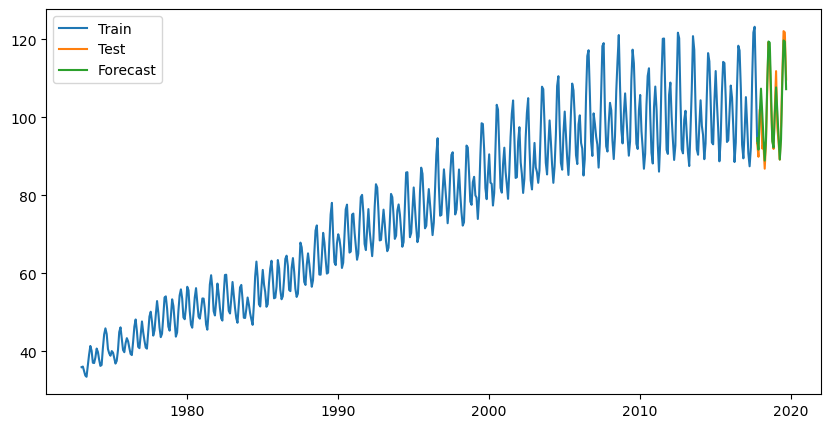

In [42]:
plt.figure(figsize=(10,5))
plt.plot(train, label='Train')
plt.plot(test, label='Test')
plt.plot(forecast, label='Forecast')
plt.legend()
plt.show()

### 20. Refit the selected SARIMA model on ALL data
This is an important step.
You do not use the model trained only until 2017 for your final 2020–2021 forecast.
Once model validation is complete, use all 561 observations to train the final model.
For the best model found in the validation above:

In [48]:
df.columns

Index(['Electricty_Consumption (TW)'], dtype='object')

In [49]:
# Final SARIMA model

final_model = SARIMAX(
    df['Electricty_Consumption (TW)'],
    order=(2,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_model_fit = final_model.fit(
    disp=False
)

print(final_model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:        Electricty_Consumption (TW)   No. Observations:                  561
Model:             SARIMAX(2, 1, 1)x(1, 1, 1, 12)   Log Likelihood               -1078.088
Date:                            Tue, 06 Oct 2026   AIC                           2168.176
Time:                                    17:04:37   BIC                           2193.858
Sample:                                01-01-1973   HQIC                          2178.225
                                     - 09-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6453      0.042     15.283      0.000       0.563       0.728
ar.L2         -0.1196      0.045   

####  21. Forecast next 24 months
Using the model that's fitted for the entire data, forecast is carried out for next 24 months. 

In [50]:
# Forecast next 24 months

forecast_steps = 24

forecast = final_model_fit.forecast(
    steps=forecast_steps
)

# Create future dates
future_dates = pd.date_range(
    start=df.index[-1] + pd.offsets.MonthBegin(1),
    periods=forecast_steps,
    freq='MS'
)

# Create forecast dataframe
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecast_Electricity_Consumption_TW': forecast.values
})

print(forecast_df)

         Date  Forecast_Electricity_Consumption_TW
0  2019-10-01                            96.774121
1  2019-11-01                            93.680799
2  2019-12-01                           103.028898
3  2020-01-01                           109.331192
4  2020-02-01                            99.646076
5  2020-03-01                            95.816689
6  2020-04-01                            90.084882
7  2020-05-01                            96.440849
8  2020-06-01                           110.470037
9  2020-07-01                           121.624291
10 2020-08-01                           120.636779
11 2020-09-01                           108.468585
12 2020-10-01                            96.371966
13 2020-11-01                            93.839248
14 2020-12-01                           103.447619
15 2021-01-01                           109.850778
16 2021-02-01                           100.199687
17 2021-03-01                            96.380153
18 2021-04-01                  

### 22. Plot final forecast
The forecast results are plotted along with the original data.

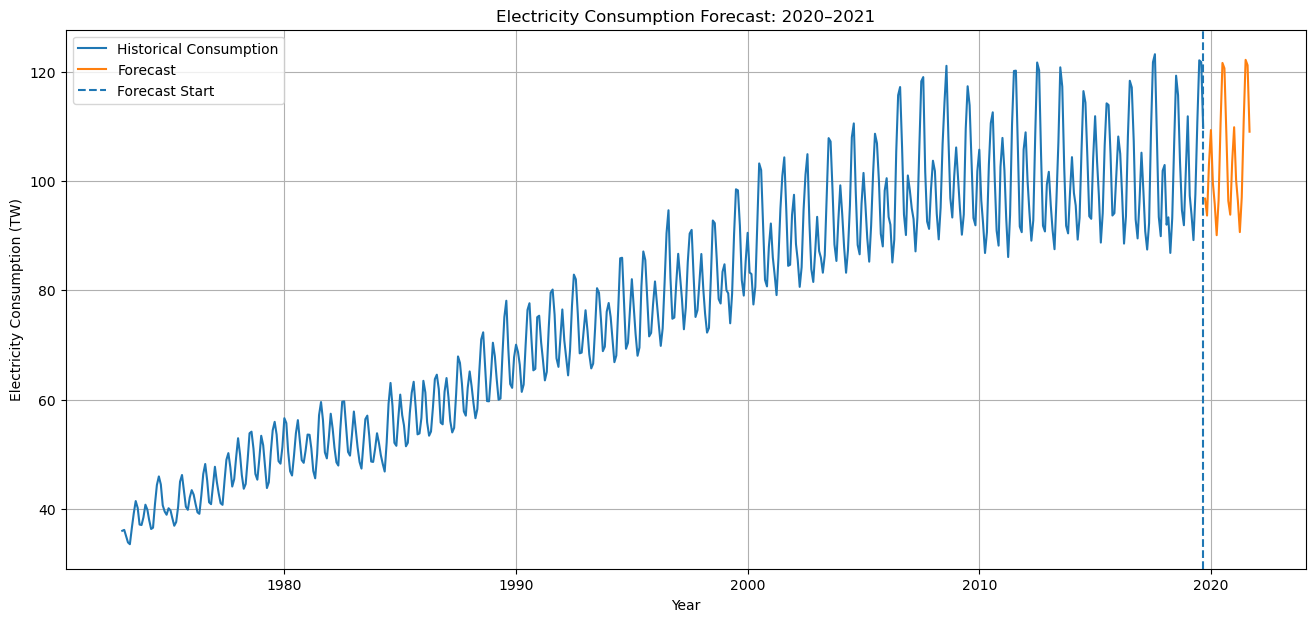

In [52]:
plt.figure(figsize=(16, 7))

# Historical data
plt.plot(
    df.index,
    df['Electricty_Consumption (TW)'],
    label='Historical Consumption'
)

# Forecast
plt.plot(
    future_dates,
    forecast,
    label='Forecast'
)

# Mark forecast starting point
plt.axvline(
    df.index[-1],
    linestyle='--',
    label='Forecast Start'
)

plt.title(
    "Electricity Consumption Forecast: 2020–2021"
)

plt.xlabel("Year")
plt.ylabel("Electricity Consumption (TW)")

plt.legend()
plt.grid(True)
plt.show()

### 24. Exporting the forecast
The forecast results are exported to a .csv file.

In [53]:
# Save forecast to CSV

forecast_df.to_csv(
    "Electricity_Demand_Forecast_2020_2021.csv",
    index=False
)

print(
    "Forecast saved successfully."
)

Forecast saved successfully.
